In [1]:
import pandas as pd

In [5]:
df = pd.read_csv("labeled_data.csv")
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

PermissionError: [Errno 13] Permission denied: 'labeled_data.csv'

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Everything is working!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Everything is working!
NumPy: 2.4.6
Pandas: 3.0.5


In [8]:
import pandas as pd

df = pd.read_csv("Labeled_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head(10))

PermissionError: [Errno 13] Permission denied: 'Labeled_data.csv'

In [10]:
import os

path = "Labeled_data.csv"

print("Current folder:")
print(os.getcwd())

print("\nFile exists:", os.path.exists(path))
print("Is it a file:", os.path.isfile(path))
print("Is it a folder:", os.path.isdir(path))

if os.path.exists(path):
    print("File size:", os.path.getsize(path), "bytes")

Current folder:
c:\Users\DHIRAJ\OneDrive\Desktop\aies project

File exists: True
Is it a file: False
Is it a folder: True
File size: 0 bytes


In [12]:
import pandas as pd

df = pd.read_csv("labeled_data.csv/labeled_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head(10))

Dataset loaded successfully!
Shape: (24783, 7)
Columns: ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'tweet']


,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...
5,5,3,1,2,0,1,"!!!!!!!!!!!!!!!!!!""@T_Madison_x: The shit just..."
6,6,3,0,3,0,1,"!!!!!!""@__BrighterDays: I can not just sit up ..."
7,7,3,0,3,0,1,!!!!&#8220;@selfiequeenbri: cause I'm tired of...
8,8,3,0,3,0,1,""" &amp; you might not get ya bitch back &amp; ..."
9,9,3,1,2,0,1,""" @rhythmixx_ :hobbies include: fighting Maria..."


In [14]:
import pandas as pd

# Load the dataset (note the nested path based on your folder structure)
df = pd.read_csv("labeled_data.csv/labeled_data.csv")

# Basic shape and structure
print("Shape (rows, columns):", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)

Shape (rows, columns): (24783, 7)

Column names: ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'tweet']

Data types:
 Unnamed: 0            int64
count                 int64
hate_speech           int64
offensive_language    int64
neither               int64
class                 int64
tweet                   str
dtype: object


In [16]:
# Check for missing values and duplicates
print("Missing values per column:\n", df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values per column:
 Unnamed: 0            0
count                 0
hate_speech           0
offensive_language    0
neither               0
class                 0
tweet                 0
dtype: int64

Number of duplicate rows: 0


In [19]:
# Check how many tweets fall into each class
print(df['class'].value_counts())
print("\nAs percentages:")
print(df['class'].value_counts(normalize=True) * 100)

# Look at a few example tweets from each class
for label in sorted(df['class'].unique()):
    print(f"\n--- Class {label} examples ---")
    print(df[df['class'] == label]['tweet'].head(3).tolist())

class
1    19190
2     4163
0     1430
Name: count, dtype: int64

As percentages:
class
1    77.432111
2    16.797805
0     5.770084
Name: proportion, dtype: float64

--- Class 0 examples ---
['"@Blackman38Tide: @WhaleLookyHere @HowdyDowdy11 queer" gaywad', '"@CB_Baby24: @white_thunduh alsarabsss" hes a beaner smh you can tell hes a mexican', '"@DevilGrimz: @VigxRArts you\'re fucking gay, blacklisted hoe" Holding out for #TehGodClan anyway http://t.co/xUCcwoetmn']

--- Class 1 examples ---
['!!!!! RT @mleew17: boy dats cold...tyga dwn bad for cuffin dat hoe in the 1st place!!', '!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby4life: You ever fuck a bitch and she start to cry? You be confused as shit', '!!!!!!!!! RT @C_G_Anderson: @viva_based she look like a tranny']

--- Class 2 examples ---
["!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out...", '" momma said no pussy cats inside my doghouse "', '"@

In [21]:
import re

def clean_tweet(text):
    text = str(text)
    # Remove the "RT @username:" retweet marker
    text = re.sub(r'^RT @\w+:', '', text)
    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', '', text)
    # Remove @mentions (keep the rest of the sentence intact)
    text = re.sub(r'@\w+', '', text)
    # Collapse multiple spaces into one
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_tweet'] = df['tweet'].apply(clean_tweet)

# Compare a few before/after
for i in range(3):
    print("BEFORE:", df['tweet'].iloc[i])
    print("AFTER: ", df['clean_tweet'].iloc[i])
    print()

BEFORE: !!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out...
AFTER:  !!! RT : As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out...

BEFORE: !!!!! RT @mleew17: boy dats cold...tyga dwn bad for cuffin dat hoe in the 1st place!!
AFTER:  !!!!! RT : boy dats cold...tyga dwn bad for cuffin dat hoe in the 1st place!!

BEFORE: !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby4life: You ever fuck a bitch and she start to cry? You be confused as shit
AFTER:  !!!!!!! RT Dawg!!!! RT : You ever fuck a bitch and she start to cry? You be confused as shit



In [23]:
import re
import html

def clean_tweet(text):
    text = str(text)
    # Decode HTML entities like &amp; -> &
    text = html.unescape(text)
    # Remove "RT @username:" anywhere in the text, not just at the start
    text = re.sub(r'RT @\w+:?', '', text)
    # Remove URLs
    text = re.sub(r'http\S+|www\.\S+', '', text)
    # Remove remaining @mentions
    text = re.sub(r'@\w+', '', text)
    # Collapse multiple spaces into one
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_tweet'] = df['tweet'].apply(clean_tweet)

# Re-check the same examples
for i in range(3):
    print("BEFORE:", df['tweet'].iloc[i])
    print("AFTER: ", df['clean_tweet'].iloc[i])
    print()

BEFORE: !!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out...
AFTER:  !!! As a woman you shouldn't complain about cleaning up your house. & as a man you should always take the trash out...

BEFORE: !!!!! RT @mleew17: boy dats cold...tyga dwn bad for cuffin dat hoe in the 1st place!!
AFTER:  !!!!! boy dats cold...tyga dwn bad for cuffin dat hoe in the 1st place!!

BEFORE: !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby4life: You ever fuck a bitch and she start to cry? You be confused as shit
AFTER:  !!!!!!! Dawg!!!! You ever fuck a bitch and she start to cry? You be confused as shit



In [25]:
from sklearn.model_selection import train_test_split

X = df['clean_tweet']
y = df['class']

# First split: 80% train, 20% temp (which we'll split into val/test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: split the 20% temp into 10% val, 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train size:", len(X_train))
print("Validation size:", len(X_val))
print("Test size:", len(X_test))

# Confirm class balance is preserved across splits
print("\nTrain class %:\n", y_train.value_counts(normalize=True) * 100)
print("\nVal class %:\n", y_val.value_counts(normalize=True) * 100)
print("\nTest class %:\n", y_test.value_counts(normalize=True) * 100)

Train size: 19826
Validation size: 2478
Test size: 2479

Train class %:
 class
1    77.433673
2    16.796126
0     5.770201
Name: proportion, dtype: float64

Val class %:
 class
1    77.441485
2    16.787732
0     5.770783
Name: proportion, dtype: float64

Test class %:
 class
1    77.410246
2    16.821299
0     5.768455
Name: proportion, dtype: float64


In [27]:
import pandas as pd

def inspect_dataset(path, name, nrows_preview=5):
    print("="*70)
    print(f"DATASET: {name}")
    print("="*70)
    try:
        df = pd.read_csv(path)
    except UnicodeDecodeError:
        # Some Hinglish/Devanagari files aren't UTF-8 by default
        print("UTF-8 read failed, retrying with utf-8-sig / latin-1 fallback...")
        df = pd.read_csv(path, encoding='utf-8-sig')

    print(f"\nShape: {df.shape}")
    print(f"\nColumns: {df.columns.tolist()}")
    print(f"\nFirst {nrows_preview} rows:")
    print(df.head(nrows_preview))
    print(f"\nData types:\n{df.dtypes}")
    print(f"\nMissing values per column:\n{df.isnull().sum()}")
    print(f"\nDuplicate rows: {df.duplicated().sum()}")
    return df

In [29]:
df_hinglish = inspect_dataset(
    "csv files/combined_hate_speech_dataset.csv",
    "combined_hate_speech_dataset.csv (Hinglish)"
)

DATASET: combined_hate_speech_dataset.csv (Hinglish)

Shape: (29550, 9)

Columns: ['text', 'hate_label', 'source', 'profanity_score', 'language', 'dataset_version', 'combined_date', 'text_length', 'word_count']

First 5 rows:
                                                text  hate_label  \
0  Knowing ki Vikas kitna samjhata hai Priyanka a...           0   
1  I am Muhajir .. Aur mere lye sab se Pehly Paki...           0   
2  Doctor  sab sahi me ke PhD (in hate politics) ...           0   
3  Poore Desh me Patel OBC me aate Hain sirf gujr...           0   
4  Sarkar banne ke bad Hindu hit me ek bhi faisla...           1   

            source  profanity_score  language dataset_version combined_date  \
0  hate_speech_tsv                0  hinglish            v1.0    2025-09-11   
1  hate_speech_tsv                0  hinglish            v1.0    2025-09-11   
2  hate_speech_tsv                0  hinglish            v1.0    2025-09-11   
3  hate_speech_tsv                0  hinglish    

In [31]:
# Print unique values for any column that looks like it might be a label
for col in df_hinglish.columns:
    if df_hinglish[col].dtype == 'object' and df_hinglish[col].nunique() < 20:
        print(f"\nColumn '{col}' unique values:")
        print(df_hinglish[col].value_counts())
    elif df_hinglish[col].dtype in ['int64', 'float64'] and df_hinglish[col].nunique() < 20:
        print(f"\nColumn '{col}' unique values:")
        print(df_hinglish[col].value_counts())


Column 'hate_label' unique values:
hate_label
0    15825
1    13725
Name: count, dtype: int64

Column 'profanity_score' unique values:
profanity_score
0     29341
8        45
7        34
1        25
2        20
6        20
9        19
3        16
5        13
4        11
10        6
Name: count, dtype: int64


In [33]:
df_labeled = inspect_dataset(
    "csv files/labeled_data.csv",
    "labeled_data.csv"
)

DATASET: labeled_data.csv

Shape: (24783, 7)

Columns: ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'tweet']

First 5 rows:
   Unnamed: 0  count  hate_speech  offensive_language  neither  class  \
0           0      3            0                   0        3      2   
1           1      3            0                   3        0      1   
2           2      3            0                   3        0      1   
3           3      3            0                   2        1      1   
4           4      6            0                   6        0      1   

                                               tweet  
0  !!! RT @mayasolovely: As a woman you shouldn't...  
1  !!!!! RT @mleew17: boy dats cold...tyga dwn ba...  
2  !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...  
3  !!!!!!!!! RT @C_G_Anderson: @viva_based she lo...  
4  !!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...  

Data types:
Unnamed: 0            int64
count                 int64
ha

In [35]:
df_jigsaw = inspect_dataset(
    "csv files/train.csv",
    "Jigsaw train.csv"
)
label_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']
existing_label_cols = [c for c in label_cols if c in df_jigsaw.columns]

print("Label columns found:", existing_label_cols)
print("\nHow many labels are active per row (0 = clean comment):")
print(df_jigsaw[existing_label_cols].sum(axis=1).value_counts().sort_index())

print("\nPositive count per label:")
print(df_jigsaw[existing_label_cols].sum())

DATASET: Jigsaw train.csv

Shape: (159571, 8)

Columns: ['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

First 5 rows:
                 id                                       comment_text  toxic  \
0  0000997932d777bf  Explanation\nWhy the edits made under my usern...      0   
1  000103f0d9cfb60f  D'aww! He matches this background colour I'm s...      0   
2  000113f07ec002fd  Hey man, I'm really not trying to edit war. It...      0   
3  0001b41b1c6bb37e  "\nMore\nI can't make any real suggestions on ...      0   
4  0001d958c54c6e35  You, sir, are my hero. Any chance you remember...      0   

   severe_toxic  obscene  threat  insult  identity_hate  
0             0        0       0       0              0  
1             0        0       0       0              0  
2             0        0       0       0              0  
3             0        0       0       0              0  
4             0        0       0       0              0 

In [37]:
print("Jigsaw missing values:")
print(df_jigsaw.isnull().sum().to_string())

print("\nJigsaw duplicate rows:", df_jigsaw.duplicated().sum())

label_cols = ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

print("\nPositive count per label:")
print(df_jigsaw[label_cols].sum().to_string())

print("\nHow many labels active per row:")
print(df_jigsaw[label_cols].sum(axis=1).value_counts().sort_index().to_string())

print("\nRows with ALL labels = 0 (completely clean comments):")
print((df_jigsaw[label_cols].sum(axis=1) == 0).sum())

Jigsaw missing values:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0

Jigsaw duplicate rows: 0

Positive count per label:
toxic            15294
severe_toxic      1595
obscene           8449
threat             478
insult            7877
identity_hate     1405

How many labels active per row:
0    143346
1      6360
2      3480
3      4209
4      1760
5       385
6        31

Rows with ALL labels = 0 (completely clean comments):
143346


In [39]:
print("Hinglish shape:", df_hinglish.shape)
print("\nHinglish columns:", df_hinglish.columns.tolist())
print("\nHinglish dtypes:\n", df_hinglish.dtypes.to_string())
print("\nHinglish missing values:\n", df_hinglish.isnull().sum().to_string())
print("\nHinglish duplicates:", df_hinglish.duplicated().sum())

Hinglish shape: (29550, 9)

Hinglish columns: ['text', 'hate_label', 'source', 'profanity_score', 'language', 'dataset_version', 'combined_date', 'text_length', 'word_count']

Hinglish dtypes:
 text                 str
hate_label         int64
source               str
profanity_score    int64
language             str
dataset_version      str
combined_date        str
text_length        int64
word_count         int64

Hinglish missing values:
 text               0
hate_label         0
source             0
profanity_score    0
language           0
dataset_version    0
combined_date      0
text_length        0
word_count         0

Hinglish duplicates: 6


In [41]:
print("hate_label value counts:\n", df_hinglish['hate_label'].value_counts().to_string())

print("\nlanguage value counts:\n", df_hinglish['language'].value_counts().to_string())

print("\nsource value counts:\n", df_hinglish['source'].value_counts().to_string())

print("\nprofanity_score value counts:\n", df_hinglish['profanity_score'].value_counts().sort_index().to_string())

print("\ndataset_version value counts:\n", df_hinglish['dataset_version'].value_counts().to_string())

print("\nDuplicates:", df_hinglish.duplicated().sum())

# A few example rows per language, so we can visually confirm script/content
for lang in df_hinglish['language'].unique():
    print(f"\n--- Examples where language = {lang} ---")
    print(df_hinglish[df_hinglish['language'] == lang]['text'].head(2).tolist())

hate_label value counts:
 hate_label
0    15825
1    13725

language value counts:
 language
english     15000
hindi        9767
hinglish     4783

source value counts:
 source
english_dataset    15000
hindi_dataset       9767
hate_speech_tsv     4574
profanity_list       209

profanity_score value counts:
 profanity_score
0     29341
1        25
2        20
3        16
4        11
5        13
6        20
7        34
8        45
9        19
10        6

dataset_version value counts:
 dataset_version
v1.0    29550

Duplicates: 6

--- Examples where language = hinglish ---
['Knowing ki Vikas kitna samjhata hai Priyanka aur Itch Guard Luv ko, usne bola tha Ben wali baat me ab Sallu ne bhi agree kiya!', 'I am Muhajir .. Aur mere lye sab se Pehly Pakistan he .. agr 10 lakh Altaf Jese leaders bh is zameen ki behurmati kren un sbko sar e aam phansi Deni chahye .. Proud to be a #Muhajir and #Pakistani']

--- Examples where language = hindi ---
['तभी अगर उन दलितों का कोई गला घोंट देता', 'जापान 

In [43]:
print("dataset_version value counts:\n", df_hinglish['dataset_version'].value_counts().to_string())
print("\nHinglish duplicates:", df_hinglish.duplicated().sum())

print("\n--- labeled_data.csv ---")
print("labeled_data shape:", df_labeled.shape)
print("labeled_data columns:", df_labeled.columns.tolist())
print("class value counts:\n", df_labeled['class'].value_counts().to_string())

dataset_version value counts:
 dataset_version
v1.0    29550

Hinglish duplicates: 6

--- labeled_data.csv ---
labeled_data shape: (24783, 7)
labeled_data columns: ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'tweet']
class value counts:
 class
1    19190
2     4163
0     1430


In [46]:
import pandas as pd

# ---- 1. Davidson (labeled_data.csv) ----
df_davidson = df_labeled.copy()
label_map_davidson = {0: 'hate', 1: 'offensive', 2: 'safe'}
df_davidson['label'] = df_davidson['class'].map(label_map_davidson)
df_davidson['text'] = df_davidson['tweet']
df_davidson['language'] = 'english'
df_davidson['source'] = 'davidson'
df_davidson = df_davidson[['text', 'label', 'language', 'source']]

# ---- 2. Jigsaw (train.csv) ----
df_j = df_jigsaw.copy()

def jigsaw_label(row):
    if row['threat'] == 1:
        return 'threat'
    elif row['identity_hate'] == 1:
        return 'hate'
    elif row['toxic'] == 1 or row['obscene'] == 1 or row['insult'] == 1 or row['severe_toxic'] == 1:
        return 'offensive'
    else:
        return 'safe'

df_j['label'] = df_j.apply(jigsaw_label, axis=1)
df_j['text'] = df_j['comment_text']
df_j['language'] = 'english'
df_j['source'] = 'jigsaw'
df_j = df_j[['text', 'label', 'language', 'source']]

# ---- 3. Hinglish (combined_hate_speech_dataset.csv) ----
df_h = df_hinglish.copy()
df_h = df_h.drop_duplicates()  # drop the 6 duplicates we found
label_map_hinglish = {0: 'safe', 1: 'hate'}
df_h['label'] = df_h['hate_label'].map(label_map_hinglish)
df_h['source'] = 'hinglish_combined'
df_h = df_h[['text', 'label', 'language', 'source']]

# ---- Combine all three ----
combined = pd.concat([df_davidson, df_j, df_h], ignore_index=True)

print("Combined shape before cleaning:", combined.shape)
print("\nLabel distribution:\n", combined['label'].value_counts().to_string())
print("\nLanguage distribution:\n", combined['language'].value_counts().to_string())

# Clean: drop empty text, drop exact duplicate texts across the whole combined set
combined['text'] = combined['text'].astype(str).str.strip()
combined = combined[combined['text'].str.len() > 0]
combined = combined.drop_duplicates(subset='text')

print("Combined shape after cleaning:", combined.shape)
print("\nFinal label distribution:\n", combined['label'].value_counts().to_string())
print("\nFinal language distribution:\n", combined['language'].value_counts().to_string())

Combined shape before cleaning: (213898, 4)

Label distribution:
 label
safe         163328
offensive     33630
hate          16462
threat          478

Language distribution:
 language
english     199349
hindi         9766
hinglish      4783
Combined shape after cleaning: (213852, 4)

Final label distribution:
 label
safe         163296
offensive     33630
hate          16448
threat          478

Final language distribution:
 language
english     199328
hindi         9744
hinglish      4780


In [48]:
import pandas as pd

target_safe_size = 49444  # brings total to ~100,000

safe_rows = combined[combined['label'] == 'safe']
non_safe_rows = combined[combined['label'] != 'safe']

# Stratified sampling of 'safe' rows, proportional to language,
# so we don't accidentally drop most Hindi/Hinglish examples
safe_sampled = (
    safe_rows.groupby('language', group_keys=False)
    .apply(lambda g: g.sample(
        n=min(len(g), int(target_safe_size * len(g) / len(safe_rows))),
        random_state=42
    ))
)

final_df = pd.concat([non_safe_rows, safe_sampled], ignore_index=True)
final_df = final_df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print("Final combined shape:", final_df.shape)
print("\nLabel distribution:\n", final_df['label'].value_counts().to_string())
print("\nLanguage distribution:\n", final_df['language'].value_counts().to_string())
print("\nSource distribution:\n", final_df['source'].value_counts().to_string())

Final combined shape: (99998, 4)

Label distribution:
 label
safe         49442
offensive    33630
hate         16448
threat         478

Language distribution:
 language
english     44342
hindi        4348
hinglish     1866

Source distribution:
 source
jigsaw               59614
davidson             21909
hinglish_combined    18475


In [50]:
import os

# Create the dataset/ folder if it doesn't exist
os.makedirs("dataset", exist_ok=True)

# Save the full combined dataset
final_df.to_csv("dataset/combined_100k.csv", index=False)
print("Saved dataset/combined_100k.csv")



Saved dataset/combined_100k.csv


In [52]:
from sklearn.model_selection import train_test_split

X = final_df['text']
y = final_df['label']
meta = final_df[['language', 'source']]  # keep alongside for reference

# First split: 80% train, 20% temp
X_train, X_temp, y_train, y_temp, meta_train, meta_temp = train_test_split(
    X, y, meta,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 10% val, 10% test from the 20% temp
X_val, X_test, y_val, y_test, meta_val, meta_test = train_test_split(
    X_temp, y_temp, meta_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Reassemble into full DataFrames and save
train_df = pd.concat([X_train, y_train, meta_train], axis=1)
val_df = pd.concat([X_val, y_val, meta_val], axis=1)
test_df = pd.concat([X_test, y_test, meta_test], axis=1)

train_df.to_csv("dataset/train.csv", index=False)
val_df.to_csv("dataset/validation.csv", index=False)
test_df.to_csv("dataset/test.csv", index=False)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain label %:\n", (y_train.value_counts(normalize=True) * 100).to_string())
print("\nVal label %:\n", (y_val.value_counts(normalize=True) * 100).to_string())
print("\nTest label %:\n", (y_test.value_counts(normalize=True) * 100).to_string())

Train: (79998, 4)
Validation: (10000, 4)
Test: (10000, 4)

Train label %:
 label
safe         49.443736
offensive    33.630841
hate         16.447911
threat        0.477512

Val label %:
 label
safe         49.44
offensive    33.63
hate         16.45
threat        0.48

Test label %:
 label
safe         49.44
offensive    33.63
hate         16.45
threat        0.48


In [54]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
label_encoder.fit(final_df['label'])

print("Label classes and their encoded values:")
for i, cls in enumerate(label_encoder.classes_):
    print(f"{i} -> {cls}")

y_train_enc = label_encoder.transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

Label classes and their encoded values:
0 -> hate
1 -> offensive
2 -> safe
3 -> threat


TF-IDF feature matrix shape (train): (79998, 15000)
              precision    recall  f1-score   support

        hate       0.62      0.75      0.68      1645
   offensive       0.86      0.81      0.83      3363
        safe       0.91      0.86      0.88      4944
      threat       0.30      0.71      0.42        48

    accuracy                           0.83     10000
   macro avg       0.67      0.78      0.70     10000
weighted avg       0.84      0.83      0.83     10000



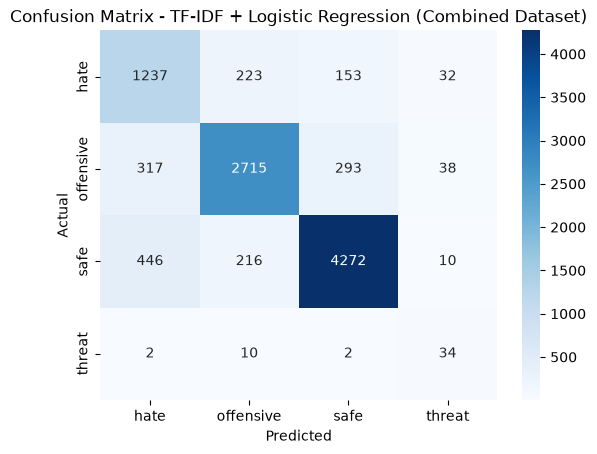

In [56]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    stop_words=None  # keep None: stop word lists are English-only and would hurt Hindi/Hinglish text
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature matrix shape (train):", X_train_tfidf.shape)

log_reg = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

log_reg.fit(X_train_tfidf, y_train_enc)
y_val_pred = log_reg.predict(X_val_tfidf)

print(classification_report(y_val_enc, y_val_pred, target_names=label_encoder.classes_))

cm = confusion_matrix(y_val_enc, y_val_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - TF-IDF + Logistic Regression (Combined Dataset)')
plt.show()

In [57]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

ModuleNotFoundError: No module named 'torch'

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("PyTorch version:", torch.__version__)

CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch version: 2.11.0+cu128


In [2]:
import numpy as np
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

X_train_dense = X_train_tfidf.toarray().astype(np.float32)
X_val_dense = X_val_tfidf.toarray().astype(np.float32)
X_test_dense = X_test_tfidf.toarray().astype(np.float32)

class TfidfDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = TfidfDataset(X_train_dense, y_train_enc)
val_dataset = TfidfDataset(X_val_dense, y_val_enc)
test_dataset = TfidfDataset(X_test_dense, y_test_enc)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("Input feature size:", X_train_dense.shape[1])

Using device: cuda


NameError: name 'X_train_tfidf' is not defined

In [3]:
import pandas as pd

train_df = pd.read_csv("dataset/train.csv")
val_df = pd.read_csv("dataset/validation.csv")
test_df = pd.read_csv("dataset/test.csv")

X_train = train_df['text'].astype(str)
y_train = train_df['label']
X_val = val_df['text'].astype(str)
y_val = val_df['label']
X_test = test_df['text'].astype(str)
y_test = test_df['label']

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (79998,) Val: (10000,) Test: (10000,)


In [4]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
label_encoder.fit(y_train)
y_train_enc = label_encoder.transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

for i, cls in enumerate(label_encoder.classes_):
    print(f"{i} -> {cls}")

0 -> hate
1 -> offensive
2 -> safe
3 -> threat


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), stop_words=None)
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)
print("TF-IDF shape (train):", X_train_tfidf.shape)

TF-IDF shape (train): (79998, 15000)


In [6]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

X_train_dense = X_train_tfidf.toarray().astype(np.float32)
X_val_dense = X_val_tfidf.toarray().astype(np.float32)
X_test_dense = X_test_tfidf.toarray().astype(np.float32)

class TfidfDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(TfidfDataset(X_train_dense, y_train_enc), batch_size=64, shuffle=True)
val_loader = DataLoader(TfidfDataset(X_val_dense, y_val_enc), batch_size=64, shuffle=False)
test_loader = DataLoader(TfidfDataset(X_test_dense, y_test_enc), batch_size=64, shuffle=False)

Using device: cuda


MemoryError: Unable to allocate 4.47 GiB for an array with shape (79998, 15000) and data type float32

In [7]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class TfidfSparseDataset(Dataset):
    def __init__(self, X_sparse, y):
        self.X = X_sparse  # keep as sparse matrix, don't densify
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, idx):
        # convert only THIS ONE row to dense — tiny, not 4.5GB
        row = self.X[idx].toarray().squeeze().astype(np.float32)
        return torch.tensor(row), self.y[idx]

train_loader = DataLoader(TfidfSparseDataset(X_train_tfidf, y_train_enc), batch_size=64, shuffle=True)
val_loader = DataLoader(TfidfSparseDataset(X_val_tfidf, y_val_enc), batch_size=64, shuffle=False)
test_loader = DataLoader(TfidfSparseDataset(X_test_tfidf, y_test_enc), batch_size=64, shuffle=False)

print("Setup complete, no memory error")

Using device: cuda
Setup complete, no memory error


In [8]:
import torch.nn as nn

class SimpleANN(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(SimpleANN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

model_ann = SimpleANN(
    input_size=X_train_tfidf.shape[1],
    hidden_size=128,
    num_classes=len(label_encoder.classes_)
).to(device)

print(model_ann)

SimpleANN(
  (fc1): Linear(in_features=15000, out_features=128, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=128, out_features=4, bias=True)
)


In [9]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_ann.parameters(), lr=0.001)

num_epochs = 10

for epoch in range(num_epochs):
    model_ann.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model_ann(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    model_ann.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model_ann(X_batch)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == y_batch).sum().item()
            total += y_batch.size(0)

    val_acc = correct / total
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {avg_loss:.4f} - Val Accuracy: {val_acc:.4f}")

Epoch 1/10 - Loss: 0.5003 - Val Accuracy: 0.8357
Epoch 2/10 - Loss: 0.3357 - Val Accuracy: 0.8345
Epoch 3/10 - Loss: 0.2605 - Val Accuracy: 0.8277
Epoch 4/10 - Loss: 0.1857 - Val Accuracy: 0.8278
Epoch 5/10 - Loss: 0.1279 - Val Accuracy: 0.8175
Epoch 6/10 - Loss: 0.0908 - Val Accuracy: 0.8148
Epoch 7/10 - Loss: 0.0702 - Val Accuracy: 0.8137
Epoch 8/10 - Loss: 0.0542 - Val Accuracy: 0.8096
Epoch 9/10 - Loss: 0.0444 - Val Accuracy: 0.8086
Epoch 10/10 - Loss: 0.0370 - Val Accuracy: 0.8092


In [10]:
import torch.nn as nn

class SimpleANN(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, dropout=0.3):
        super(SimpleANN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout)
        self.fc3 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        x = self.dropout1(self.relu1(self.fc1(x)))
        x = self.dropout2(self.relu2(self.fc2(x)))
        x = self.fc3(x)
        return x

model_ann = SimpleANN(
    input_size=X_train_tfidf.shape[1],
    hidden_size=128,
    num_classes=len(label_encoder.classes_),
    dropout=0.3
).to(device)

print(model_ann)

SimpleANN(
  (fc1): Linear(in_features=15000, out_features=128, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=128, out_features=4, bias=True)
)


In [11]:
import torch.optim as optim
import copy

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_ann.parameters(), lr=0.001)

num_epochs = 10
best_val_acc = 0
best_model_state = None

for epoch in range(num_epochs):
    model_ann.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model_ann(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    model_ann.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model_ann(X_batch)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == y_batch).sum().item()
            total += y_batch.size(0)

    val_acc = correct / total
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {avg_loss:.4f} - Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model_ann.state_dict())
        print(f"  -> New best model saved (val acc: {val_acc:.4f})")

# Load the best-performing epoch's weights back into the model
model_ann.load_state_dict(best_model_state)
print(f"\nLoaded best model with validation accuracy: {best_val_acc:.4f}")

Epoch 1/10 - Loss: 0.5248 - Val Accuracy: 0.8314
  -> New best model saved (val acc: 0.8314)
Epoch 2/10 - Loss: 0.3493 - Val Accuracy: 0.8323
  -> New best model saved (val acc: 0.8323)
Epoch 3/10 - Loss: 0.2727 - Val Accuracy: 0.8321
Epoch 4/10 - Loss: 0.2052 - Val Accuracy: 0.8286
Epoch 5/10 - Loss: 0.1540 - Val Accuracy: 0.8257
Epoch 6/10 - Loss: 0.1202 - Val Accuracy: 0.8227
Epoch 7/10 - Loss: 0.0966 - Val Accuracy: 0.8216
Epoch 8/10 - Loss: 0.0801 - Val Accuracy: 0.8190
Epoch 9/10 - Loss: 0.0686 - Val Accuracy: 0.8203
Epoch 10/10 - Loss: 0.0586 - Val Accuracy: 0.8172

Loaded best model with validation accuracy: 0.8323


c:\Users\DHIRAJ\miniconda3\envs\aies\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\DHIRAJ\miniconda3\envs\aies\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\DHIRAJ\miniconda3\envs\aies\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh

              precision    recall  f1-score   support

        hate       0.68      0.66      0.67      1645
   offensive       0.81      0.86      0.84      3363
        safe       0.90      0.88      0.89      4944
      threat       0.00      0.00      0.00        48

    accuracy                           0.83     10000
   macro avg       0.60      0.60      0.60     10000
weighted avg       0.83      0.83      0.83     10000



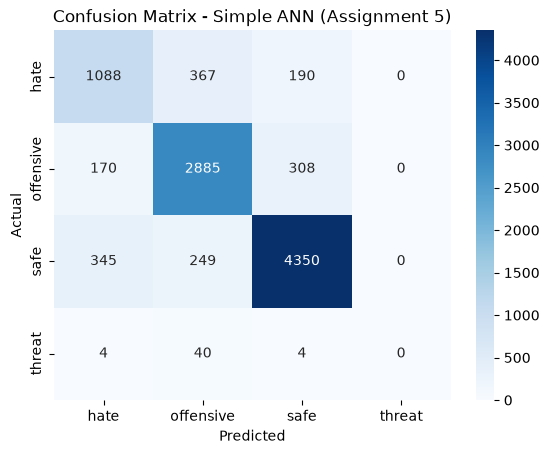

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model_ann.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        outputs = model_ann(X_batch)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(y_batch.numpy())

print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Simple ANN (Assignment 5)')
plt.show()

In [13]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Compute class weights inversely proportional to class frequency
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_enc),
    y=y_train_enc
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class weights:")
for cls, weight in zip(label_encoder.classes_, class_weights):
    print(f"{cls}: {weight:.3f}")

Class weights:
hate: 1.520
offensive: 0.743
safe: 0.506
threat: 52.355


In [14]:
import torch.optim as optim
import copy

model_ann = SimpleANN(
    input_size=X_train_tfidf.shape[1],
    hidden_size=128,
    num_classes=len(label_encoder.classes_),
    dropout=0.3
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)  # <-- key change
optimizer = optim.Adam(model_ann.parameters(), lr=0.001)

num_epochs = 10
best_val_acc = 0
best_model_state = None

for epoch in range(num_epochs):
    model_ann.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model_ann(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    model_ann.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model_ann(X_batch)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == y_batch).sum().item()
            total += y_batch.size(0)

    val_acc = correct / total
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{num_epochs} - Loss: {avg_loss:.4f} - Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_state = copy.deepcopy(model_ann.state_dict())
        print(f"  -> New best model saved (val acc: {val_acc:.4f})")

model_ann.load_state_dict(best_model_state)
print(f"\nLoaded best model with validation accuracy: {best_val_acc:.4f}")

Epoch 1/10 - Loss: 0.7722 - Val Accuracy: 0.8060
  -> New best model saved (val acc: 0.8060)
Epoch 2/10 - Loss: 0.4603 - Val Accuracy: 0.8143
  -> New best model saved (val acc: 0.8143)
Epoch 3/10 - Loss: 0.3297 - Val Accuracy: 0.8103
Epoch 4/10 - Loss: 0.2584 - Val Accuracy: 0.8115
Epoch 5/10 - Loss: 0.2090 - Val Accuracy: 0.8125
Epoch 6/10 - Loss: 0.1668 - Val Accuracy: 0.8092
Epoch 7/10 - Loss: 0.1333 - Val Accuracy: 0.8070
Epoch 8/10 - Loss: 0.1153 - Val Accuracy: 0.8031
Epoch 9/10 - Loss: 0.0994 - Val Accuracy: 0.8088
Epoch 10/10 - Loss: 0.0887 - Val Accuracy: 0.8065

Loaded best model with validation accuracy: 0.8143


              precision    recall  f1-score   support

        hate       0.63      0.74      0.68      1645
   offensive       0.84      0.80      0.82      3363
        safe       0.91      0.85      0.88      4944
      threat       0.13      0.77      0.22        48

    accuracy                           0.81     10000
   macro avg       0.63      0.79      0.65     10000
weighted avg       0.84      0.81      0.82     10000



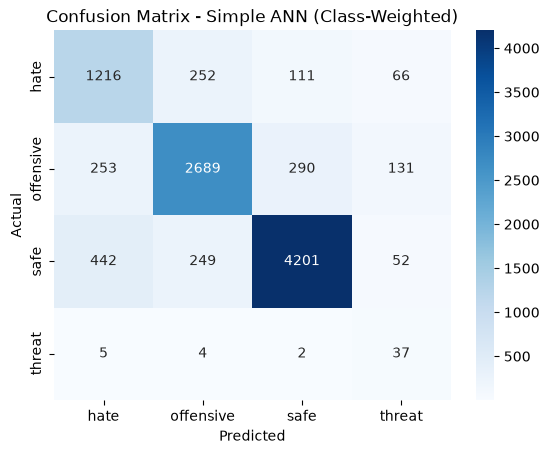

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model_ann.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        outputs = model_ann(X_batch)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(y_batch.numpy())

print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Simple ANN (Class-Weighted)')
plt.show()

In [16]:
import os

os.makedirs("model/ann", exist_ok=True)

torch.save(model_ann.state_dict(), "model/ann/ann_model_final.pt")

import joblib
joblib.dump(tfidf, "model/ann/tfidf_vectorizer.pkl")
joblib.dump(label_encoder, "model/ann/label_encoder.pkl")
joblib.dump(class_weights_tensor.cpu().numpy(), "model/ann/class_weights.pkl")

print("Final ANN model, TF-IDF vectorizer, label encoder, and class weights saved.")

Final ANN model, TF-IDF vectorizer, label encoder, and class weights saved.


In [17]:
from transformers import AutoTokenizer

# We use the multilingual variant since your dataset has English, Hindi, and Hinglish
model_checkpoint = "distilbert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

# Try it on one example from each language to see how it handles them
sample_texts = [
    train_df[train_df['language'] == 'english']['text'].iloc[0],
    train_df[train_df['language'] == 'hindi']['text'].iloc[0],
    train_df[train_df['language'] == 'hinglish']['text'].iloc[0],
]

for text in sample_texts:
    print("Original:", text)
    tokens = tokenizer.tokenize(text)
    print("Tokens:", tokens)
    print("Token IDs:", tokenizer.convert_tokens_to_ids(tokens))
    print()

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

c:\Users\DHIRAJ\miniconda3\envs\aies\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DHIRAJ\.cache\huggingface\hub\models--distilbert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Original: RT @_JioVanni: These bitches play on everybody's team
Tokens: ['RT', '@', '_', 'Ji', '##o', '##V', '##ann', '##i', ':', 'These', 'bit', '##ches', 'play', 'on', 'every', '##body', "'", 's', 'team']
Token IDs: [56898, 137, 168, 30822, 10133, 11779, 20801, 10116, 131, 13252, 17684, 16272, 12253, 10135, 14234, 38078, 112, 187, 11121]

Original: अफसोस इस बात का नही की धर्म का धंधा हो रहा है 
अफसोस इस बात का है कि पढ़ा लिखा अंधा हो रहा है
Tokens: ['अ', '##फ', '##स', '##ो', '##स', 'इस', 'बात', 'का', 'न', '##ही', 'की', 'धर्म', 'का', 'ध', '##ं', '##धा', 'हो', 'रहा', 'है', 'अ', '##फ', '##स', '##ो', '##स', 'इस', 'बात', 'का', 'है', 'कि', 'प', '##ढ़', '##ा', 'ल', '##िखा', 'अ', '##ं', '##धा', 'हो', 'रहा', 'है']
Token IDs: [851, 28863, 13432, 13718, 13432, 14265, 70811, 11081, 884, 24667, 10826, 24589, 11081, 883, 14018, 38380, 13220, 36475, 10569, 851, 28863, 13432, 13718, 13432, 14265, 70811, 11081, 10569, 14117, 885, 89027, 11208, 893, 105968, 851, 14018, 38380, 13220, 36475, 10569]

Ori

In [18]:
# Tokenize all three splits
def tokenize_texts(text_series, max_length=128):
    return tokenizer(
        text_series.tolist(),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    )

train_encodings = tokenize_texts(X_train)
val_encodings = tokenize_texts(X_val)
test_encodings = tokenize_texts(X_test)

print("Train input_ids shape:", train_encodings['input_ids'].shape)
print("Train attention_mask shape:", train_encodings['attention_mask'].shape)

Train input_ids shape: torch.Size([79998, 128])
Train attention_mask shape: torch.Size([79998, 128])


In [19]:
from torch.utils.data import Dataset

class HateSpeechDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

train_dataset_bert = HateSpeechDataset(train_encodings, y_train_enc)
val_dataset_bert = HateSpeechDataset(val_encodings, y_val_enc)
test_dataset_bert = HateSpeechDataset(test_encodings, y_test_enc)

print("Train dataset size:", len(train_dataset_bert))
print("Sample item keys:", train_dataset_bert[0].keys())

Train dataset size: 79998
Sample item keys: dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])


In [2]:
from transformers import AutoModelForSequenceClassification

num_labels = len(label_encoder.classes_)

model_bert = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=num_labels
)

model_bert.to(device)

 print(f"Model loaded with {num_labels} output classes: {list(label_encoder.classes_)}")

IndentationError: unexpected indent (1605174574.py, line 12)

In [3]:
import pandas as pd
import numpy as np
import torch

train_df = pd.read_csv("dataset/train.csv")
val_df = pd.read_csv("dataset/validation.csv")
test_df = pd.read_csv("dataset/test.csv")

X_train = train_df['text'].astype(str)
y_train = train_df['label']
X_val = val_df['text'].astype(str)
y_val = val_df['label']
X_test = test_df['text'].astype(str)
y_test = test_df['label']

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [4]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
label_encoder.fit(y_train)
y_train_enc = label_encoder.transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

for i, cls in enumerate(label_encoder.classes_):
    print(f"{i} -> {cls}")

0 -> hate
1 -> offensive
2 -> safe
3 -> threat


In [5]:
from transformers import AutoTokenizer

model_checkpoint = "distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
print("Tokenizer loaded.")

Tokenizer loaded.


In [6]:
def tokenize_texts(text_series, max_length=128):
    return tokenizer(
        text_series.tolist(),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    )

train_encodings = tokenize_texts(X_train)
val_encodings = tokenize_texts(X_val)
test_encodings = tokenize_texts(X_test)
print("Tokenization done. Shape:", train_encodings['input_ids'].shape)

Tokenization done. Shape: torch.Size([79998, 128])


In [7]:
from torch.utils.data import Dataset

class HateSpeechDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

train_dataset_bert = HateSpeechDataset(train_encodings, y_train_enc)
val_dataset_bert = HateSpeechDataset(val_encodings, y_val_enc)
test_dataset_bert = HateSpeechDataset(test_encodings, y_test_enc)
print("Datasets ready. Train size:", len(train_dataset_bert))

Datasets ready. Train size: 79998


In [8]:
from transformers import AutoModelForSequenceClassification

num_labels = len(label_encoder.classes_)

model_bert = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=num_labels
)
model_bert.to(device)

print(f"Model loaded with {num_labels} output classes: {list(label_encoder.classes_)}")

c:\Users\DHIRAJ\miniconda3\envs\aies\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DHIRAJ\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\Users\DHIRAJ\miniconda3\envs\aies\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DHIRAJ\.cache\huggingface\hub\models--distilbert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded with 4 output classes: ['hate', 'offensive', 'safe', 'threat']


In [9]:
print(f"Model loaded with {num_labels} output classes: {list(label_encoder.classes_)}")
print("Model device:", next(model_bert.parameters()).device)

Model loaded with 4 output classes: ['hate', 'offensive', 'safe', 'threat']
Model device: cuda:0


In [10]:
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='macro', zero_division=0)
    acc = accuracy_score(labels, predictions)
    return {'accuracy': acc, 'macro_f1': f1, 'macro_precision': precision, 'macro_recall': recall}

training_args = TrainingArguments(
    output_dir='./distilbert_checkpoints',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    logging_dir='./logs',
    logging_steps=100,
    fp16=True,
)

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_dataset_bert,
    eval_dataset=val_dataset_bert,
    compute_metrics=compute_metrics,
)

print("Trainer set up. Ready to train.")

TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'logging_dir'

In [11]:
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='macro', zero_division=0)
    acc = accuracy_score(labels, predictions)
    return {'accuracy': acc, 'macro_f1': f1, 'macro_precision': precision, 'macro_recall': recall}

training_args = TrainingArguments(
    output_dir='./distilbert_checkpoints',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    logging_steps=100,
    fp16=True,
)

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_dataset_bert,
    eval_dataset=val_dataset_bert,
    compute_metrics=compute_metrics,
)

print("Trainer set up. Ready to train.")

Trainer set up. Ready to train.


In [1]:
trainer.train()

NameError: name 'trainer' is not defined

In [2]:
import pandas as pd
import numpy as np
import torch

train_df = pd.read_csv("dataset/train.csv")
val_df = pd.read_csv("dataset/validation.csv")

X_train = train_df['text'].astype(str)
y_train = train_df['label']
X_val = val_df['text'].astype(str)
y_val = val_df['label']

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
label_encoder.fit(y_train)
y_train_enc = label_encoder.transform(y_train)
y_val_enc = label_encoder.transform(y_val)

for i, cls in enumerate(label_encoder.classes_):
    print(f"{i} -> {cls}")

0 -> hate
1 -> offensive
2 -> safe
3 -> threat


In [4]:
from transformers import AutoTokenizer

model_checkpoint = "distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

def tokenize_texts(text_series, max_length=128):
    return tokenizer(text_series.tolist(), padding='max_length', truncation=True, max_length=max_length, return_tensors='pt')

train_encodings = tokenize_texts(X_train)
val_encodings = tokenize_texts(X_val)
print("Tokenized. Shape:", train_encodings['input_ids'].shape)

Tokenized. Shape: torch.Size([79998, 128])


In [5]:
from torch.utils.data import Dataset

class HateSpeechDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

train_dataset_bert = HateSpeechDataset(train_encodings, y_train_enc)
val_dataset_bert = HateSpeechDataset(val_encodings, y_val_enc)
print("Datasets ready:", len(train_dataset_bert), len(val_dataset_bert))

Datasets ready: 79998 10000


In [6]:
from transformers import AutoModelForSequenceClassification

num_labels = len(label_encoder.classes_)
model_bert = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=num_labels)
model_bert.to(device)
print("Model on:", next(model_bert.parameters()).device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model on: cuda:0


In [7]:
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average='macro', zero_division=0)
    acc = accuracy_score(labels, predictions)
    return {'accuracy': acc, 'macro_f1': f1, 'macro_precision': precision, 'macro_recall': recall}

training_args = TrainingArguments(
    output_dir='./distilbert_checkpoints',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    logging_steps=100,
    fp16=True,
)

trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_dataset_bert,
    eval_dataset=val_dataset_bert,
    compute_metrics=compute_metrics,
)

print("Trainer ready.")

Trainer ready.


In [8]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.305147,0.317820,0.877400,0.646501,0.638279,0.657462
2,0.244796,0.307081,0.884900,0.713476,0.837796,0.699817
3,0.143404,0.385512,0.885200,0.765823,0.787078,0.751821


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=15000, training_loss=0.262874240620931, metrics={'train_runtime': 1646.6655, 'train_samples_per_second': 145.745, 'train_steps_per_second': 9.109, 'total_flos': 7948128695334912.0, 'train_loss': 0.262874240620931, 'epoch': 3.0})

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_recall_fscore_support
)

In [10]:
predictions = trainer.predict(eval_dataset)

logits = predictions.predictions
true_labels = predictions.label_ids

predicted_labels = np.argmax(logits, axis=-1)

print("Predictions generated successfully!")
print("Number of predictions:", len(predicted_labels))

NameError: name 'eval_dataset' is not defined

              precision    recall  f1-score   support

        hate       0.78      0.80      0.79      1645
   offensive       0.88      0.91      0.89      3363
        safe       0.93      0.90      0.92      4944
      threat       0.56      0.40      0.46        48

    accuracy                           0.89     10000
   macro avg       0.79      0.75      0.77     10000
weighted avg       0.89      0.89      0.89     10000



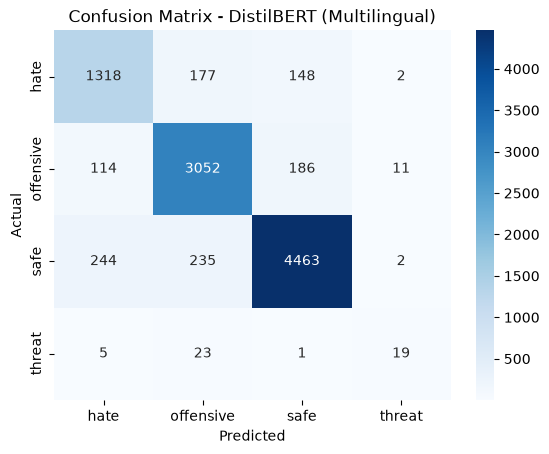

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model_bert.eval()
all_preds = []
all_labels = []

from torch.utils.data import DataLoader
val_loader_bert = DataLoader(val_dataset_bert, batch_size=32)

with torch.no_grad():
    for batch in val_loader_bert:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels']

        outputs = model_bert(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - DistilBERT (Multilingual)')
plt.show()

In [12]:
import os

os.makedirs("model/distilbert_final", exist_ok=True)
model_bert.save_pretrained("model/distilbert_final")
tokenizer.save_pretrained("model/distilbert_final")

print("DistilBERT model and tokenizer saved to model/distilbert_final")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model and tokenizer saved to model/distilbert_final
